# Compresión de Imágenes mediante Quadtrees utilizando Divide y Vencerás

**Universidad Nacional Autónoma de México**  
**Facultad de Estudios Superiores Aragón**  
**Ingeniería en Computación**

**Asignatura:** Diseño y Análisis de Algoritmos  
**Alumnos:**  
*   Borja Hernández Joshua
*   Torres Hilario Andrik

**Profesor:** Sanchez Sanchez Victor Manuel
**Grupo:** 1510  
**Fecha:** 09/10/2026

---

## Descripción del proyecto

Este proyecto desarrolla un algoritmo de compresión de imágenes basado en la estructura de datos Quadtree, utilizando la estrategia de Divide y Vencerás.

El algoritmo analiza una imagen y la divide recursivamente en regiones rectangulares. Cada región se evalúa mediante el error cuadrático medio (MSE) de sus componentes RGB. Si el error se encuentra dentro de una tolerancia establecida, la región se representa mediante su color promedio; de lo contrario, se subdivide para continuar el análisis.

La implementación permite realizar compresión con y sin pérdida, reconstruir imágenes, almacenar los resultados en archivos binarios `.qtr` y recuperar las imágenes posteriormente.

Además, se analiza la complejidad temporal mediante recurrencias y el Teorema Maestro, complementando los resultados teóricos con mediciones experimentales de tiempo de ejecución, almacenamiento y calidad de reconstrucción.

## Objetivo general

Diseñar, implementar y analizar un algoritmo de compresión de imágenes mediante Quadtrees que aplique la estrategia de Divide y Vencerás, evaluando su eficiencia computacional y el compromiso entre calidad visual y almacenamiento.

---
## 1. Bibliotecas y configuración del entorno

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import struct
import time

from pathlib import Path

## 2. Implementación del algoritmo Quadtree

En esta sección se implementa la estructura Quadtree utilizando
la estrategia de Divide y Vencerás.

El algoritmo analiza cada región de la imagen, calcula su color
promedio y su error cuadrático medio (MSE), y determina si debe
representarla mediante una hoja o subdividirla recursivamente.

1. NodoQuadtree - Representar cada región del árbol
2. analizar_region() - Calcular color promedio y MSE
3. dividir_region() - Dividir una región en subregiones
4. construir_quadtree() - Aplicar Divide y Vencerás recursivamente
5. reconstruir_quadtree() - Recuperar la imagen desde las hojas
6. obtener_metricas_arbol() - Contar nodos, hojas y profundidad


In [2]:
class NodoQuadtree:
    def __init__(self, x, y, ancho, alto, color=None):
        self.x = x
        self.y = y
        self.ancho = ancho
        self.alto = alto
        self.color = color
        self.hijos = []

    def es_hoja(self):
        return len(self.hijos) == 0

In [3]:
def analizar_region(imagen, x, y, ancho, alto):
    region = imagen[y:y + alto, x:x + ancho]

    if region.size == 0:
        raise ValueError("La región no puede estar vacía")

    region_float = region.astype(np.float64)

    color_promedio = np.mean(
        region_float,
        axis=(0, 1)
    )

    mse = np.mean(
        (region_float - color_promedio) ** 2
    )

    return color_promedio, float(mse)

In [4]:
def dividir_region(x, y, ancho, alto):
    mitad_ancho = ancho // 2
    mitad_alto = alto // 2

    regiones = [
        (x, y, mitad_ancho, mitad_alto),
        (x + mitad_ancho, y,
         ancho - mitad_ancho, mitad_alto),
        (x, y + mitad_alto,
         mitad_ancho, alto - mitad_alto),
        (x + mitad_ancho, y + mitad_alto,
         ancho - mitad_ancho, alto - mitad_alto)
    ]

    return [
        region for region in regiones
        if region[2] > 0 and region[3] > 0
    ]

In [5]:
def construir_quadtree(
    imagen, x, y, ancho, alto, tolerancia=0
):
    color_promedio, mse = analizar_region(
        imagen, x, y, ancho, alto
    )

    nodo = NodoQuadtree(
        x, y, ancho, alto,
        color=color_promedio
    )

    # Caso base
    if mse <= tolerancia or (ancho == 1 and alto == 1):
        return nodo

    # Dividir y resolver recursivamente
    regiones = dividir_region(x, y, ancho, alto)

    for cx, cy, ca, ch in regiones:
        hijo = construir_quadtree(
            imagen, cx, cy, ca, ch, tolerancia
        )
        nodo.hijos.append(hijo)

    return nodo

In [6]:
def reconstruir_quadtree(arbol):
    imagen = np.zeros(
        (arbol.alto, arbol.ancho, 3),
        dtype=np.uint8
    )

    def pintar(nodo):
        if nodo.es_hoja():
            color = np.clip(
                np.rint(nodo.color), 0, 255
            ).astype(np.uint8)

            imagen[
                nodo.y:nodo.y + nodo.alto,
                nodo.x:nodo.x + nodo.ancho
            ] = color
        else:
            for hijo in nodo.hijos:
                pintar(hijo)

    pintar(arbol)

    return imagen

In [7]:
def obtener_metricas_arbol(arbol):
    metricas = {
        "nodos_totales": 0,
        "nodos_internos": 0,
        "hojas": 0,
        "profundidad_maxima": 0
    }

    def recorrer(nodo, profundidad):
        metricas["nodos_totales"] += 1

        metricas["profundidad_maxima"] = max(
            metricas["profundidad_maxima"],
            profundidad
        )

        if nodo.es_hoja():
            metricas["hojas"] += 1
        else:
            metricas["nodos_internos"] += 1

            for hijo in nodo.hijos:
                recorrer(hijo, profundidad + 1)

    recorrer(arbol, 0)

    return metricas

In [8]:
# Imagen de prueba: cuatro regiones de color
imagen_test = np.zeros((8, 8, 3), dtype=np.uint8)

imagen_test[:4, :4] = [255, 0, 0]
imagen_test[:4, 4:] = [0, 255, 0]
imagen_test[4:, :4] = [0, 0, 255]
imagen_test[4:, 4:] = [255, 255, 0]

# Construir el árbol
arbol_test = construir_quadtree(
    imagen_test, 0, 0, 8, 8, tolerancia=0
)

# Reconstruir la imagen
reconstruida_test = reconstruir_quadtree(arbol_test)

# Obtener métricas
metricas_test = obtener_metricas_arbol(arbol_test)

print("PRUEBA DE FUNCIONES PRINCIPALES")
print("-" * 45)
print("Nodos totales:", metricas_test["nodos_totales"])
print("Hojas:", metricas_test["hojas"])
print("Profundidad:", metricas_test["profundidad_maxima"])
print(
    "Reconstrucción exacta:",
    np.array_equal(imagen_test, reconstruida_test)
)

assert metricas_test["nodos_totales"] == 5
assert metricas_test["hojas"] == 4
assert np.array_equal(imagen_test, reconstruida_test)

print("\nFunciones principales: CORRECTAS")

PRUEBA DE FUNCIONES PRINCIPALES
---------------------------------------------
Nodos totales: 5
Hojas: 4
Profundidad: 1
Reconstrucción exacta: True

Funciones principales: CORRECTAS


## 3. Compresión y descompresión binaria

Una vez construido el Quadtree, es necesario almacenar su estructura y los colores de sus hojas para permitir la recuperación posterior de la imagen.

Se utiliza un formato binario propio con extensión `.qtr`, basado en un recorrido en preorden del árbol.

Cada nodo se representa mediante un bit:

- **0:** nodo hoja, seguido de tres bytes que representan su color RGB.
- **1:** nodo interno, seguido de la representación recursiva de sus hijos.

Los bits de estructura se empaquetan en grupos de ocho para reducir el almacenamiento.

El archivo incluye una cabecera de 16 bytes con el identificador del formato, las dimensiones originales y la cantidad de bits de estructura.

Esta representación permite almacenar el árbol y reconstruir la imagen sin depender de la imagen original.

In [9]:
def serializar_quadtree(nodo):
    """
    Convierte el Quadtree en bits de estructura
    y bytes de colores RGB mediante preorden.
    """

    bits = []
    colores = bytearray()

    def recorrer(actual):
        if actual.es_hoja():
            bits.append(0)

            rgb = np.clip(
                np.rint(actual.color),
                0, 255
            ).astype(np.uint8)

            colores.extend(rgb.tolist())

        else:
            bits.append(1)

            for hijo in actual.hijos:
                recorrer(hijo)

    recorrer(nodo)

    return bits, bytes(colores)


def empaquetar_bits(bits):
    """
    Agrupa ocho bits por byte.
    """

    resultado = bytearray()

    for inicio in range(0, len(bits), 8):
        grupo = bits[inicio:inicio + 8]

        valor = 0

        for bit in grupo:
            valor = (valor << 1) | bit

        valor <<= (8 - len(grupo))
        resultado.append(valor)

    return bytes(resultado)


def desempaquetar_bits(datos, cantidad_bits):
    """
    Recupera los bits de estructura.
    """

    bits = []

    for byte in datos:
        for desplazamiento in range(7, -1, -1):
            bit = (byte >> desplazamiento) & 1
            bits.append(bit)

            if len(bits) == cantidad_bits:
                return bits

    if len(bits) != cantidad_bits:
        raise ValueError(
            "Datos insuficientes para recuperar los bits"
        )

    return bits

In [10]:
def deserializar_quadtree(bits, colores, ancho, alto):
    """
    Recupera el Quadtree desde los bits
    de estructura y los bytes RGB.
    """

    indice_bit = 0
    indice_color = 0

    def reconstruir_nodo(x, y, w, h):
        nonlocal indice_bit, indice_color

        if w <= 0 or h <= 0:
            raise ValueError("Dimensiones inválidas")

        if indice_bit >= len(bits):
            raise ValueError("Faltan bits de estructura")

        bit = bits[indice_bit]
        indice_bit += 1

        if bit == 0:
            if indice_color + 3 > len(colores):
                raise ValueError("Faltan datos RGB")

            rgb = np.frombuffer(
                colores[indice_color:indice_color + 3],
                dtype=np.uint8
            ).astype(np.float64)

            indice_color += 3

            return NodoQuadtree(
                x, y, w, h, color=rgb
            )

        if bit != 1:
            raise ValueError("Bit de estructura inválido")

        if w == 1 and h == 1:
            raise ValueError("Un píxel no puede subdividirse")

        nodo = NodoQuadtree(
            x, y, w, h, color=None
        )

        cuadrantes = dividir_region(x, y, w, h)

        for cx, cy, ca, ch in cuadrantes:
            hijo = reconstruir_nodo(
                cx, cy, ca, ch
            )

            nodo.hijos.append(hijo)

        return nodo

    raiz = reconstruir_nodo(
        0, 0, ancho, alto
    )

    if indice_bit != len(bits):
        raise ValueError("Sobran bits de estructura")

    if indice_color != len(colores):
        raise ValueError("Sobran bytes de colores")

    return raiz

In [11]:
def guardar_quadtree(raiz, ruta):
    """
    Guarda un árbol en un archivo binario .qtr.
    """

    bits, colores = serializar_quadtree(raiz)
    estructura = empaquetar_bits(bits)

    cabecera = struct.pack(
        "<4sIII",
        b"QTR1",
        raiz.ancho,
        raiz.alto,
        len(bits)
    )

    with open(ruta, "wb") as archivo:
        archivo.write(cabecera)
        archivo.write(estructura)
        archivo.write(colores)

    return {
        "ruta": str(ruta),
        "bytes_cabecera": len(cabecera),
        "bytes_estructura": len(estructura),
        "bytes_colores": len(colores),
        "bytes_totales": Path(ruta).stat().st_size
    }


def cargar_quadtree(ruta):
    """
    Lee un archivo .qtr y recupera su árbol.
    """

    with open(ruta, "rb") as archivo:
        cabecera = archivo.read(16)

        if len(cabecera) != 16:
            raise ValueError("Archivo incompleto: falta cabecera")

        identificador, ancho, alto, cantidad_bits = (
            struct.unpack("<4sIII", cabecera)
        )

        if identificador != b"QTR1":
            raise ValueError("Formato de archivo no reconocido")

        if ancho == 0 or alto == 0 or cantidad_bits == 0:
            raise ValueError("Cabecera con valores inválidos")

        bytes_estructura = (cantidad_bits + 7) // 8
        estructura = archivo.read(bytes_estructura)

        if len(estructura) != bytes_estructura:
            raise ValueError("Archivo incompleto: falta estructura")

        colores = archivo.read()

    bits = desempaquetar_bits(
        estructura, cantidad_bits
    )

    return deserializar_quadtree(
        bits, colores, ancho, alto
    )

In [12]:
print("PRUEBA DEL SISTEMA DE COMPRESIÓN")
print("-" * 45)

# Guardar el árbol
informacion = guardar_quadtree(
    arbol_test,
    "prueba_final.qtr"
)

# Recuperar desde el archivo
arbol_recuperado = cargar_quadtree(
    "prueba_final.qtr"
)

# Reconstruir imagen
imagen_recuperada = reconstruir_quadtree(
    arbol_recuperado
)

# Verificar resultados
identica = np.array_equal(
    imagen_test,
    imagen_recuperada
)

print("Tamaño original:", imagen_test.nbytes, "bytes")
print("Tamaño .qtr:", informacion["bytes_totales"], "bytes")
print("Reconstrucción exacta:", identica)

assert identica
assert informacion["bytes_totales"] == 29

print("\nCompresión y descompresión: CORRECTAS")

PRUEBA DEL SISTEMA DE COMPRESIÓN
---------------------------------------------
Tamaño original: 192 bytes
Tamaño .qtr: 29 bytes
Reconstrucción exacta: True

Compresión y descompresión: CORRECTAS


## 4. Análisis de complejidad temporal

### 4.1 Estrategia de Divide y Vencerás

El algoritmo Quadtree aplica la estrategia de Divide y Vencerás mediante tres etapas:

**Dividir:** Se analiza una región de la imagen y, si su error cuadrático medio (MSE) supera la tolerancia establecida, se subdivide en hasta cuatro subregiones.

**Vencer:** Se aplica recursivamente el mismo procedimiento a cada subregión. La recursión termina cuando el MSE es menor o igual a la tolerancia, o cuando la región contiene un solo píxel.

**Combinar:** Los árboles obtenidos para cada subregión se incorporan como hijos del nodo actual, formando la estructura Quadtree.

### 4.2 Recurrencia temporal

Sea N el número total de píxeles de una imagen cuadrada, cuyas dimensiones son potencias de dos.

En el peor caso, todas las regiones deben subdividirse hasta alcanzar píxeles individuales.

En cada llamada recursiva:

- Se analiza la región actual, con un costo de Θ(N).
- Se divide la región en cuatro subregiones de N/4 píxeles.
- Se construye recursivamente un Quadtree para cada subregión.
- Se incorporan los nodos hijos al árbol, con un costo adicional constante.

Por tanto, la recurrencia es:

**T(N) = 4T(N/4) + Θ(N)**

Condición base:

**T(1) = Θ(1)**

### 4.3 Resolución mediante el Teorema Maestro

La forma general del Teorema Maestro es:

**T(N) = aT(N/b) + f(N)**

Identificamos los siguientes valores:

- a = 4
- b = 4
- f(N) = Θ(N)

Calculamos el término de comparación:

**N^(log_b a) = N^(log₄ 4) = N¹ = N**

Por lo tanto:

**f(N) = Θ(N^(log_b a)) = Θ(N)**

Como f(N) tiene el mismo orden de crecimiento que N^(log_b a), se cumple el **caso 2 del Teorema Maestro**.

La solución es:

**T(N) = Θ(N log N)**

Esto significa que la complejidad temporal de construcción del Quadtree, en el peor caso, es Θ(N log N).

### 4.4 Mejor caso

El mejor caso ocurre cuando toda la imagen satisface el criterio de tolerancia y puede representarse mediante una sola hoja.

Aunque no se realizan subdivisiones, el algoritmo necesita analizar los N píxeles para calcular el color promedio y el MSE.

Por tanto:

**T_mejor(N) = Θ(N)**

### 4.5 Complejidad de reconstrucción

La reconstrucción recorre las hojas del Quadtree y asigna un color a cada región.

Como las hojas representan regiones que, en conjunto, cubren todos los píxeles de la imagen, el trabajo total de escritura es proporcional a N.

Por tanto:

**T_reconstrucción(N) = Θ(N)**

### 4.6 Complejidad espacial

En el peor caso, cada píxel se representa mediante una hoja y el Quadtree contiene Θ(N) nodos.

Por tanto, el almacenamiento del árbol requiere:

**S_árbol(N) = Θ(N)**

Para imágenes cuadradas equilibradas, la profundidad máxima del árbol es Θ(log N), por lo que la pila de llamadas recursivas necesita O(log N) espacio adicional.

La imagen reconstruida ocupa Θ(N) espacio.

Además, la implementación utiliza arreglos temporales de NumPy para calcular estadísticas de las regiones, por lo que el consumo de memoria de trabajo puede incluir almacenamiento temporal proporcional al tamaño de la región analizada.

### 4.7 Interpretación del resultado

La recurrencia T(N) = 4T(N/4) + Θ(N) indica que cada problema se divide en cuatro subproblemas, cada uno con una cuarta parte de los píxeles.

En el peor caso, el trabajo total realizado en cada nivel del árbol de recurrencia es Θ(N).

Como existen aproximadamente log₄(N) + 1 niveles, el trabajo total se expresa como:

**T(N) = Θ(N) × Θ(log N)**

Por lo tanto:

**T(N) = Θ(N log N)**

Este resultado representa el comportamiento asintótico del algoritmo en el peor caso. Los tiempos experimentales pueden variar según las características de la imagen, la tolerancia seleccionada y el entorno de ejecución.

## 5. Pruebas experimentales y validación

El objetivo de esta sección es comprobar el funcionamiento del algoritmo Quadtree utilizando imágenes con diferentes características y dimensiones.

Se consideran tres tipos de imágenes:

- **Imagen uniforme:** todos los píxeles tienen el mismo color. Permite evaluar el mejor caso del algoritmo, donde la imagen se representa mediante una sola hoja.
- **Imagen por regiones:** contiene cuatro regiones de colores uniformes. Permite verificar que el algoritmo identifica áreas homogéneas y evita subdivisiones innecesarias.
- **Imagen aleatoria:** contiene píxeles RGB generados aleatoriamente. Permite estudiar escenarios donde existen numerosas subdivisiones y el almacenamiento puede aumentar.

Las pruebas se realizan utilizando diferentes tamaños de imagen y valores de tolerancia.

Para evaluar los resultados se consideran las siguientes métricas:

- Tiempo de construcción del Quadtree.
- Tiempo de reconstrucción de la imagen.
- Número total de nodos y hojas.
- Profundidad máxima del árbol.
- Error cuadrático medio (MSE).
- Tamaño de los datos RGB originales y del archivo comprimido.
- Razón de compresión y porcentaje de ahorro.

Estas mediciones permiten contrastar el comportamiento experimental con el análisis teórico de complejidad.

In [13]:
def generar_imagen_prueba(tipo, tamaño, semilla=42):
    """
    Genera imágenes RGB para experimentación.

    Tipos:
    - uniforme
    - regiones
    - aleatoria
    """

    if tamaño <= 0:
        raise ValueError("El tamaño debe ser positivo")

    if tipo == "uniforme":
        imagen = np.zeros(
            (tamaño, tamaño, 3),
            dtype=np.uint8
        )
        imagen[:] = [100, 150, 200]

    elif tipo == "regiones":
        imagen = np.zeros(
            (tamaño, tamaño, 3),
            dtype=np.uint8
        )

        mitad = tamaño // 2

        imagen[:mitad, :mitad] = [255, 0, 0]
        imagen[:mitad, mitad:] = [0, 255, 0]
        imagen[mitad:, :mitad] = [0, 0, 255]
        imagen[mitad:, mitad:] = [255, 255, 0]

    elif tipo == "aleatoria":
        generador = np.random.default_rng(semilla)

        imagen = generador.integers(
            0, 256,
            size=(tamaño, tamaño, 3),
            dtype=np.uint8
        )

    else:
        raise ValueError(
            "Tipo no válido. Use uniforme, regiones o aleatoria."
        )

    return imagen

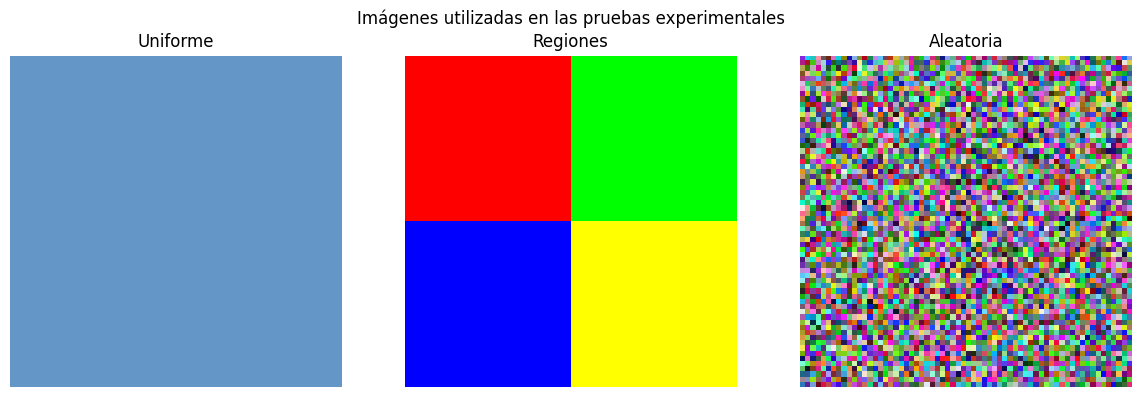

In [14]:
tipos = ["uniforme", "regiones", "aleatoria"]

fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, tipo in zip(ejes, tipos):

    imagen_prueba = generar_imagen_prueba(
        tipo, 64
    )

    eje.imshow(imagen_prueba)
    eje.set_title(tipo.capitalize())
    eje.axis("off")

plt.suptitle(
    "Imágenes utilizadas en las pruebas experimentales"
)

plt.tight_layout()
plt.show()

In [15]:
print("VALIDACIÓN DE IMÁGENES DE PRUEBA")
print("-" * 55)

for tipo in ["uniforme", "regiones", "aleatoria"]:

    img = generar_imagen_prueba(tipo, 64)

    arbol = construir_quadtree(
        img, 0, 0, 64, 64, tolerancia=0
    )

    reconstruida = reconstruir_quadtree(arbol)
    metricas = obtener_metricas_arbol(arbol)

    exacta = np.array_equal(img, reconstruida)

    print(f"\nTipo: {tipo}")
    print("Nodos:", metricas["nodos_totales"])
    print("Hojas:", metricas["hojas"])
    print("Profundidad:", metricas["profundidad_maxima"])
    print("Reconstrucción exacta:", exacta)

    assert exacta

print("\nTodas las imágenes fueron procesadas correctamente.")

VALIDACIÓN DE IMÁGENES DE PRUEBA
-------------------------------------------------------

Tipo: uniforme
Nodos: 1
Hojas: 1
Profundidad: 0
Reconstrucción exacta: True

Tipo: regiones
Nodos: 5
Hojas: 4
Profundidad: 1
Reconstrucción exacta: True

Tipo: aleatoria
Nodos: 5461
Hojas: 4096
Profundidad: 6
Reconstrucción exacta: True

Todas las imágenes fueron procesadas correctamente.


### 5.1 Medición de tiempos de ejecución

Para evaluar el rendimiento del algoritmo se realizan mediciones del tiempo necesario para construir el Quadtree y reconstruir la imagen.

Se utilizan imágenes de diferentes tamaños y características: uniformes, divididas en regiones y aleatorias.

Cada medición se repite cinco veces y se utiliza la mediana como resultado representativo, con el objetivo de reducir la influencia de variaciones ocasionales en el entorno de ejecución.

Los tiempos se expresan en milisegundos (ms).

El propósito de estas pruebas es comparar el comportamiento experimental del algoritmo con el análisis teórico de complejidad, especialmente el mejor caso O(N) y el peor caso O(N log N), donde N representa el número de píxeles.

In [16]:
from time import perf_counter
from statistics import median

def medir_tiempos(imagen, tolerancia=0, repeticiones=5):
    """
    Mide tiempos de construcción y reconstrucción.

    Devuelve las medianas en milisegundos.
    """

    if repeticiones < 1:
        raise ValueError("Debe realizarse al menos una repetición")

    alto, ancho = imagen.shape[:2]

    tiempos_construccion = []
    tiempos_reconstruccion = []

    for _ in range(repeticiones):

        inicio = perf_counter()

        arbol = construir_quadtree(
            imagen, 0, 0,
            ancho, alto,
            tolerancia
        )

        fin = perf_counter()

        tiempos_construccion.append(
            (fin - inicio) * 1000
        )

        inicio = perf_counter()

        reconstruir_quadtree(arbol)

        fin = perf_counter()

        tiempos_reconstruccion.append(
            (fin - inicio) * 1000
        )

    return {
        "construccion_ms": median(tiempos_construccion),
        "reconstruccion_ms": median(tiempos_reconstruccion)
    }

In [17]:
tamaños = [64, 128, 256]
tipos = ["uniforme", "regiones", "aleatoria"]

resultados_tiempos = []

for tipo in tipos:
    for tamaño in tamaños:

        imagen_exp = generar_imagen_prueba(
            tipo, tamaño
        )

        tiempos = medir_tiempos(
            imagen_exp,
            tolerancia=0,
            repeticiones=5
        )

        arbol_exp = construir_quadtree(
            imagen_exp,
            0, 0,
            tamaño, tamaño,
            tolerancia=0
        )

        metricas = obtener_metricas_arbol(
            arbol_exp
        )

        resultados_tiempos.append({
            "tipo": tipo,
            "tamaño": tamaño,
            "pixeles": tamaño * tamaño,
            "nodos": metricas["nodos_totales"],
            "hojas": metricas["hojas"],
            "construccion_ms": tiempos["construccion_ms"],
            "reconstruccion_ms": tiempos["reconstruccion_ms"]
        })

        print(f"Completado: {tipo} {tamaño}x{tamaño}")

df_tiempos = pd.DataFrame(resultados_tiempos)

print("\nRESULTADOS DE TIEMPOS")
display(df_tiempos.round(4))

Completado: uniforme 64x64
Completado: uniforme 128x128
Completado: uniforme 256x256
Completado: regiones 64x64
Completado: regiones 128x128
Completado: regiones 256x256
Completado: aleatoria 64x64
Completado: aleatoria 128x128
Completado: aleatoria 256x256

RESULTADOS DE TIEMPOS


,tipo,tamaño,pixeles,nodos,hojas,construccion_ms,reconstruccion_ms
0,uniforme,64,4096,1,1,0.3414,0.0988
1,uniforme,128,16384,1,1,1.1403,0.2521
2,uniforme,256,65536,1,1,5.2247,0.6217
3,regiones,64,4096,5,4,0.4598,0.0769
4,regiones,128,16384,5,4,1.2971,0.1746
5,regiones,256,65536,5,4,8.2146,0.5775
6,aleatoria,64,4096,5461,4096,148.3753,28.5700
7,aleatoria,128,16384,21845,16384,615.5008,115.4982
8,aleatoria,256,65536,87381,65536,2791.4650,465.1553


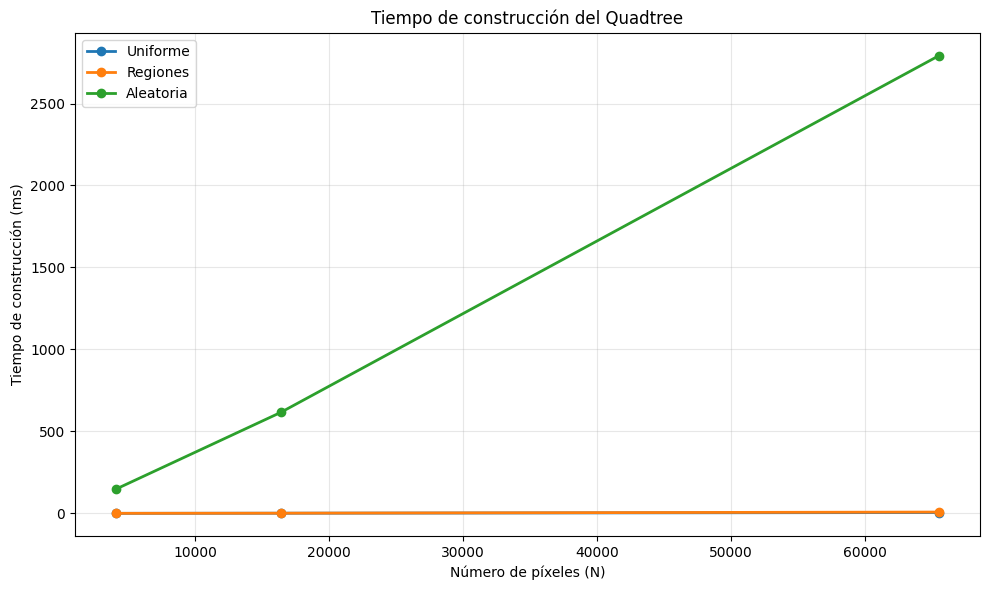

In [18]:
plt.figure(figsize=(10, 6))

for tipo in ["uniforme", "regiones", "aleatoria"]:

    datos = df_tiempos[
        df_tiempos["tipo"] == tipo
    ].sort_values("pixeles")

    plt.plot(
        datos["pixeles"],
        datos["construccion_ms"],
        marker="o",
        linewidth=2,
        label=tipo.capitalize()
    )

plt.xlabel("Número de píxeles (N)")
plt.ylabel("Tiempo de construcción (ms)")
plt.title("Tiempo de construcción del Quadtree")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "grafica_construccion_quadtree.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

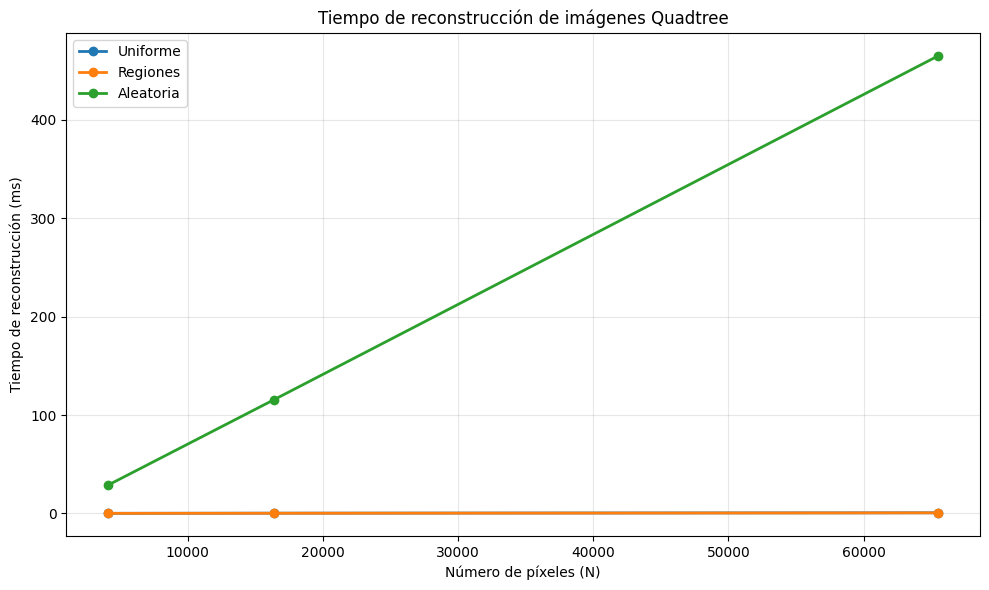

In [19]:
plt.figure(figsize=(10, 6))

for tipo in ["uniforme", "regiones", "aleatoria"]:

    datos = df_tiempos[
        df_tiempos["tipo"] == tipo
    ].sort_values("pixeles")

    plt.plot(
        datos["pixeles"],
        datos["reconstruccion_ms"],
        marker="o",
        linewidth=2,
        label=tipo.capitalize()
    )

plt.xlabel("Número de píxeles (N)")
plt.ylabel("Tiempo de reconstrucción (ms)")
plt.title("Tiempo de reconstrucción de imágenes Quadtree")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "grafica_reconstruccion_quadtree.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.2 Comparación del comportamiento experimental con el modelo teórico

El análisis mediante el Teorema Maestro establece que la construcción del Quadtree tiene una complejidad temporal de Θ(N log N) en el peor caso, donde N representa el número de píxeles.

Para contrastar este resultado con las mediciones experimentales, se utilizan las imágenes aleatorias con tolerancia cero, debido a que producen subdivisiones hasta alcanzar píxeles individuales.

Se calcula el valor N log₂(N) para cada tamaño de imagen y se ajusta mediante una constante de escala, permitiendo comparar su tendencia de crecimiento con los tiempos de ejecución medidos.

Esta comparación permite evaluar si el comportamiento observado es compatible con el modelo teórico, aunque no constituye por sí sola una demostración formal de la complejidad.

COMPARACIÓN TEÓRICA Y EXPERIMENTAL


,pixeles,construccion_ms,modelo_teorico,modelo_ajustado_ms
6,4096,148.3753,49152.0,130.8499
7,16384,615.5008,229376.0,610.6330
8,65536,2791.4650,1048576.0,2791.4650


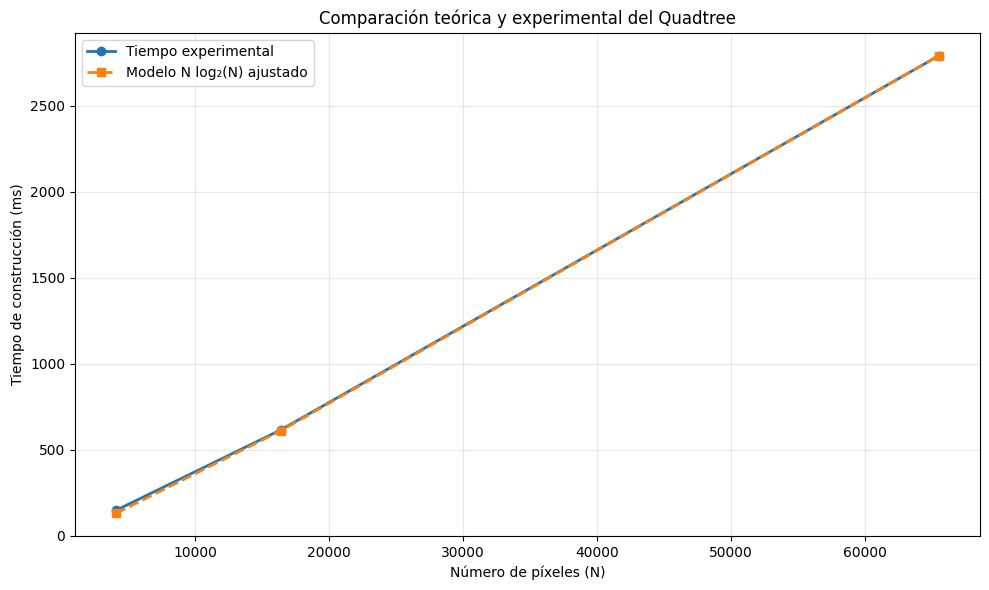

In [20]:
# Seleccionar imágenes aleatorias
df_comparacion = df_tiempos[
    df_tiempos["tipo"] == "aleatoria"
].copy()

df_comparacion = df_comparacion.sort_values("pixeles")

# Modelo teórico N log2(N)
df_comparacion["modelo_teorico"] = (
    df_comparacion["pixeles"]
    * np.log2(df_comparacion["pixeles"])
)

# Ajustar la escala utilizando el punto de mayor tamaño
constante = (
    df_comparacion["construccion_ms"].iloc[-1]
    / df_comparacion["modelo_teorico"].iloc[-1]
)

df_comparacion["modelo_ajustado_ms"] = (
    constante * df_comparacion["modelo_teorico"]
)

print("COMPARACIÓN TEÓRICA Y EXPERIMENTAL")

display(
    df_comparacion[
        [
            "pixeles",
            "construccion_ms",
            "modelo_teorico",
            "modelo_ajustado_ms"
        ]
    ].round(4)
)

plt.figure(figsize=(10, 6))

plt.plot(
    df_comparacion["pixeles"],
    df_comparacion["construccion_ms"],
    marker="o",
    linewidth=2,
    label="Tiempo experimental"
)

plt.plot(
    df_comparacion["pixeles"],
    df_comparacion["modelo_ajustado_ms"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Modelo N log₂(N) ajustado"
)

plt.xlabel("Número de píxeles (N)")
plt.ylabel("Tiempo de construcción (ms)")
plt.title("Comparación teórica y experimental del Quadtree")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "grafica_teoria_experimento_quadtree.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.3 Análisis de compresión y calidad de reconstrucción

El algoritmo Quadtree permite controlar el nivel de compresión mediante un parámetro de tolerancia basado en el error cuadrático medio (MSE).

Cuando la tolerancia es cero, el algoritmo conserva toda la información necesaria para reconstruir exactamente la imagen original.

Al aumentar la tolerancia, se permite representar regiones con variaciones de color mediante su color promedio. Esto puede disminuir el número de nodos y hojas, reduciendo el almacenamiento necesario, aunque también puede aumentar la distorsión visual.

Para evaluar este comportamiento, se utiliza una imagen aleatoria RGB de 64 × 64 píxeles con diferentes valores de tolerancia.

Se registran el número de nodos, la cantidad de hojas, el tamaño real del archivo binario `.qtr`, la razón de compresión, el porcentaje de ahorro y el MSE de la imagen recuperada.

El tamaño original se calcula considerando tres bytes por píxel RGB. Por tanto, los resultados se comparan con datos RGB sin comprimir, no con formatos como PNG o JPEG.

In [21]:
def evaluar_compresion(imagen, tolerancia, nombre_archivo):
    """
    Evalúa la compresión real mediante archivos .qtr.
    """

    alto, ancho = imagen.shape[:2]

    # Construcción
    arbol = construir_quadtree(
        imagen, 0, 0, ancho, alto, tolerancia
    )

    # Guardar archivo comprimido
    guardar_quadtree(arbol, nombre_archivo)

    # Recuperar imagen desde el archivo
    arbol_recuperado = cargar_quadtree(nombre_archivo)

    imagen_recuperada = reconstruir_quadtree(
        arbol_recuperado
    )

    # Métricas del árbol
    metricas = obtener_metricas_arbol(arbol_recuperado)

    # Error cuadrático medio
    mse = np.mean(
        (
            imagen.astype(np.float64)
            - imagen_recuperada.astype(np.float64)
        ) ** 2
    )

    # Tamaños
    bytes_originales = imagen.nbytes
    bytes_qtr = Path(nombre_archivo).stat().st_size

    razon = bytes_originales / bytes_qtr
    ahorro = (1 - bytes_qtr / bytes_originales) * 100

    return {
        "tolerancia": tolerancia,
        "nodos": metricas["nodos_totales"],
        "hojas": metricas["hojas"],
        "bytes_originales": bytes_originales,
        "bytes_qtr": bytes_qtr,
        "razon_compresion": razon,
        "ahorro_porcentaje": ahorro,
        "mse": mse
    }

In [22]:
imagen_compresion = generar_imagen_prueba(
    "aleatoria", 64, semilla=42
)

tolerancias = [
    0, 500, 2000, 5000, 10000, 20000, 30000
]

resultados_compresion = []

for tolerancia in tolerancias:

    nombre = f"compresion_tol_{tolerancia}.qtr"

    resultado = evaluar_compresion(
        imagen_compresion,
        tolerancia,
        nombre
    )

    resultados_compresion.append(resultado)

df_compresion = pd.DataFrame(
    resultados_compresion
)

print("RESULTADOS DE COMPRESIÓN REAL")

display(df_compresion.round(4))

RESULTADOS DE COMPRESIÓN REAL


,tolerancia,nodos,hojas,bytes_originales,bytes_qtr,razon_compresion,ahorro_porcentaje,mse
0,0,5461,4096,12288,12987,0.9462,-5.6885,0.0000
1,500,5457,4093,12288,12978,0.9468,-5.6152,0.3533
2,2000,5213,3910,12288,12398,0.9911,-0.8952,94.1973
3,5000,1657,1243,12288,3953,3.1085,67.8304,3370.7383
4,10000,1,1,12288,20,614.4000,99.8372,5469.5453
5,20000,1,1,12288,20,614.4000,99.8372,5469.5453
6,30000,1,1,12288,20,614.4000,99.8372,5469.5453


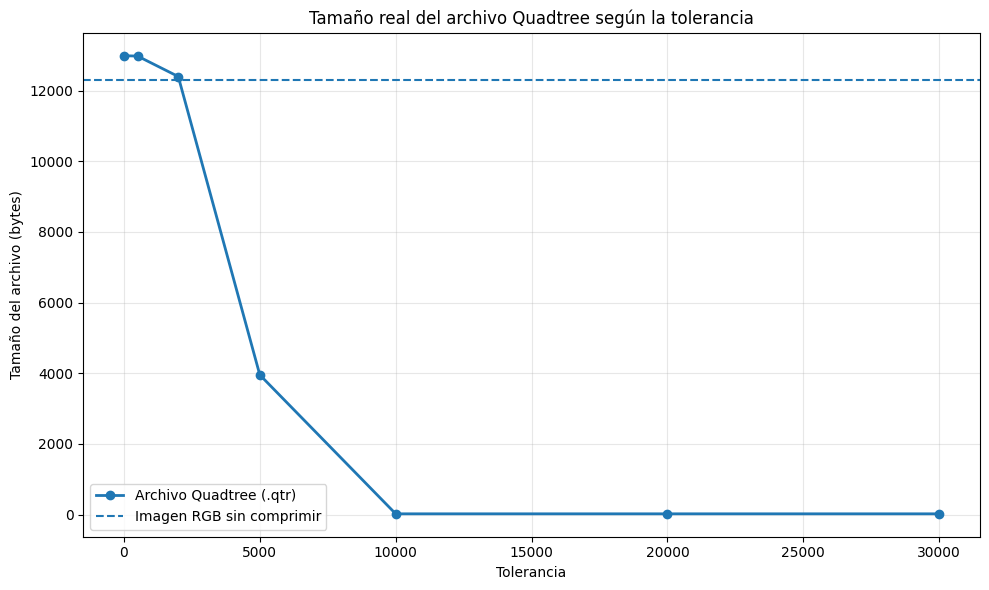

In [23]:
plt.figure(figsize=(10, 6))

plt.plot(
    df_compresion["tolerancia"],
    df_compresion["bytes_qtr"],
    marker="o",
    linewidth=2,
    label="Archivo Quadtree (.qtr)"
)

plt.axhline(
    y=imagen_compresion.nbytes,
    linestyle="--",
    label="Imagen RGB sin comprimir"
)

plt.xlabel("Tolerancia")
plt.ylabel("Tamaño del archivo (bytes)")
plt.title("Tamaño real del archivo Quadtree según la tolerancia")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "grafica_tamano_real_qtr.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

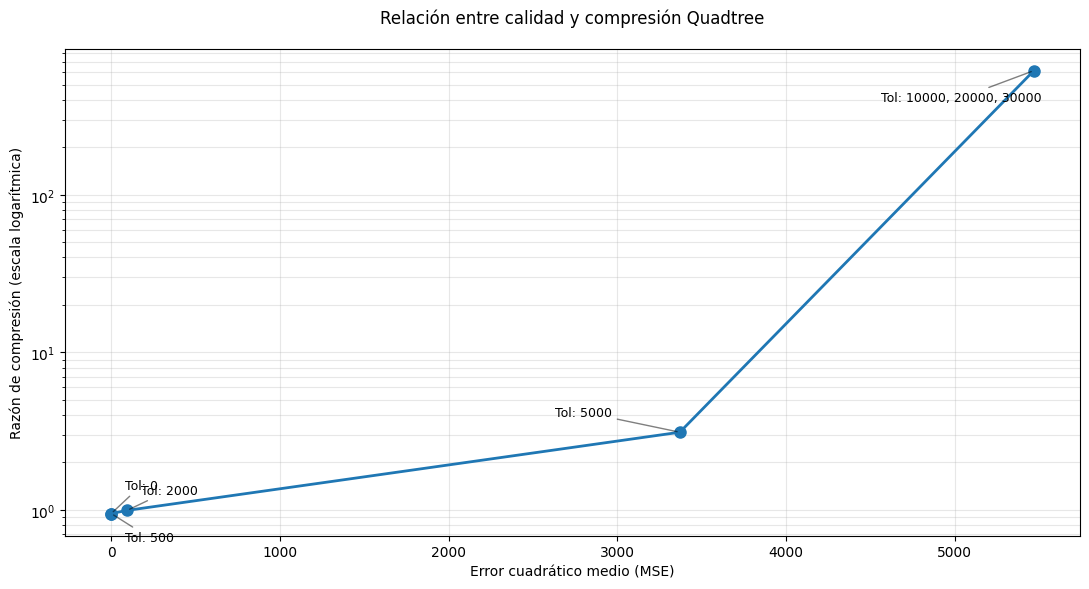

In [24]:

# Agrupar resultados que tienen el mismo MSE
# y la misma razón de compresión

df_grafica_calidad = (
    df_compresion.groupby(
        ["mse", "razon_compresion"],
        as_index=False
    )
    .agg({
        "tolerancia": lambda valores:
            ", ".join(str(int(v)) for v in valores)
    })
    .sort_values("mse")
)

plt.figure(figsize=(11, 6))

plt.plot(
    df_grafica_calidad["mse"],
    df_grafica_calidad["razon_compresion"],
    marker="o",
    linewidth=2,
    markersize=8
)

# Escala logarítmica para distinguir
# mejor las razones de compresión
plt.yscale("log")

# Etiquetas con desplazamientos diferentes
desplazamientos = [
    (10, 18),
    (10, -20),
    (10, 12),
    (-90, 12),
    (-110, -22)
]

for i, (_, fila) in enumerate(
    df_grafica_calidad.iterrows()
):

    dx, dy = desplazamientos[
        min(i, len(desplazamientos) - 1)
    ]

    plt.annotate(
        f"Tol: {fila['tolerancia']}",
        (
            fila["mse"],
            fila["razon_compresion"]
        ),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=9,
        arrowprops={
            "arrowstyle": "-",
            "alpha": 0.5
        }
    )

plt.xlabel("Error cuadrático medio (MSE)")
plt.ylabel("Razón de compresión (escala logarítmica)")
plt.title(
    "Relación entre calidad y compresión Quadtree",
    pad=18
)

plt.grid(True, alpha=0.3, which="both")

plt.tight_layout()

plt.savefig(
    "grafica_calidad_compresion_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


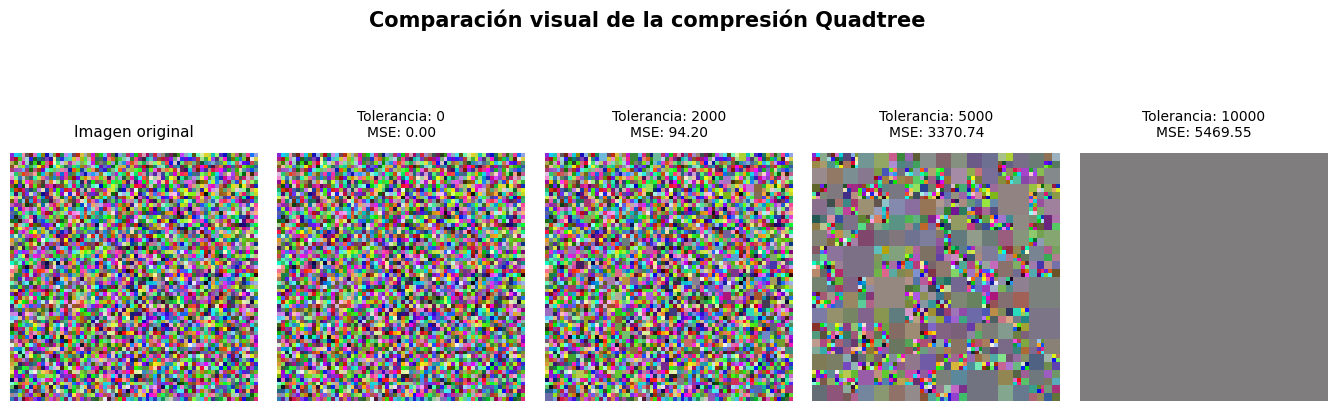

In [25]:
tolerancias_visualizacion = [
    0, 2000, 5000, 10000
]

fig, ejes = plt.subplots(
    1, 5,
    figsize=(17, 4.5)
)

# Imagen original
ejes[0].imshow(imagen_compresion)
ejes[0].set_title(
    "Imagen original",
    fontsize=11,
    pad=12
)
ejes[0].axis("off")

# Imágenes recuperadas
for i, tolerancia in enumerate(
    tolerancias_visualizacion,
    start=1
):

    nombre = f"compresion_tol_{tolerancia}.qtr"

    arbol = cargar_quadtree(nombre)
    imagen_recuperada = reconstruir_quadtree(arbol)

    mse = np.mean(
        (
            imagen_compresion.astype(np.float64)
            - imagen_recuperada.astype(np.float64)
        ) ** 2
    )

    ejes[i].imshow(imagen_recuperada)

    ejes[i].set_title(
        f"Tolerancia: {tolerancia}\nMSE: {mse:.2f}",
        fontsize=10,
        pad=12
    )

    ejes[i].axis("off")

# Título general con separación
fig.suptitle(
    "Comparación visual de la compresión Quadtree",
    fontsize=15,
    fontweight="bold",
    y=1.04
)

plt.subplots_adjust(
    top=0.78,
    wspace=0.08
)

plt.savefig(
    "grafica_comparacion_visual_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Pruebas de robustez e integridad

Además de evaluar el rendimiento del algoritmo, se realizan pruebas para verificar su correcto funcionamiento en situaciones especiales.

Se consideran los siguientes escenarios:

- **Dimensiones impares:** comprobar que una imagen de 7 × 5 píxeles puede dividirse, comprimirse y recuperarse correctamente.
- **Compresión sin pérdida:** verificar que una tolerancia de cero permite reconstruir exactamente la imagen original.
- **Compresión con pérdida:** comprobar que el archivo recuperado produce la misma reconstrucción que el árbol original.
- **Integridad del archivo:** verificar que el programa rechaza archivos con identificadores incorrectos, datos incompletos o información adicional.

Estas pruebas permiten evaluar la confiabilidad de la implementación y detectar errores relacionados con la subdivisión de regiones y la interpretación de datos binarios.

In [26]:
print("PRUEBA DE DIMENSIONES IMPARES")
print("-" * 45)

rng = np.random.default_rng(42)

imagen_impar = rng.integers(
    0, 256,
    size=(5, 7, 3),
    dtype=np.uint8
)

arbol_impar = construir_quadtree(
    imagen_impar, 0, 0, 7, 5, tolerancia=0
)

guardar_quadtree(
    arbol_impar,
    "prueba_impar_7x5.qtr"
)

arbol_recuperado_impar = cargar_quadtree(
    "prueba_impar_7x5.qtr"
)

imagen_recuperada_impar = reconstruir_quadtree(
    arbol_recuperado_impar
)

metricas_impar = obtener_metricas_arbol(
    arbol_recuperado_impar
)

print("Dimensiones:", imagen_recuperada_impar.shape)
print("Nodos:", metricas_impar["nodos_totales"])
print("Hojas:", metricas_impar["hojas"])

exacta = np.array_equal(
    imagen_impar,
    imagen_recuperada_impar
)

print("Reconstrucción exacta:", exacta)

assert exacta

print("\nPrueba de dimensiones impares: CORRECTA")

PRUEBA DE DIMENSIONES IMPARES
---------------------------------------------
Dimensiones: (5, 7, 3)
Nodos: 53
Hojas: 35
Reconstrucción exacta: True

Prueba de dimensiones impares: CORRECTA


In [27]:
print("PRUEBAS DE INTEGRIDAD")
print("-" * 45)

with open("prueba_final.qtr", "rb") as archivo:
    datos_validos = archivo.read()

archivos_invalidos = {
    "cabecera_incorrecta.qtr":
        b"XXXX" + datos_validos[4:],

    "archivo_truncado.qtr":
        datos_validos[:-3],

    "archivo_con_sobrantes.qtr":
        datos_validos + b"\x01\x02\x03"
}

rechazados = 0

for nombre, datos in archivos_invalidos.items():

    with open(nombre, "wb") as archivo:
        archivo.write(datos)

    try:
        cargar_quadtree(nombre)

        print(nombre, "-> ERROR: archivo aceptado")

    except (ValueError, TypeError) as error:
        rechazados += 1

        print(nombre, "-> RECHAZADO CORRECTAMENTE")
        print("Motivo:", error)

assert rechazados == 3

print("\nTodas las pruebas de integridad: CORRECTAS")

PRUEBAS DE INTEGRIDAD
---------------------------------------------
cabecera_incorrecta.qtr -> RECHAZADO CORRECTAMENTE
Motivo: Formato de archivo no reconocido
archivo_truncado.qtr -> RECHAZADO CORRECTAMENTE
Motivo: Faltan datos RGB
archivo_con_sobrantes.qtr -> RECHAZADO CORRECTAMENTE
Motivo: Sobran bytes de colores

Todas las pruebas de integridad: CORRECTAS


## 7. Conclusiones y posibles mejoras

### 7.1 Conclusiones

El desarrollo de este proyecto permitió implementar y analizar un algoritmo de compresión de imágenes mediante Quadtrees, aplicando la estrategia de Divide y Vencerás para descomponer recursivamente una imagen en regiones de menor tamaño.

Se comprobó que el comportamiento del algoritmo depende tanto de las dimensiones como de las características de la imagen. En las pruebas realizadas con imágenes uniformes, el Quadtree se representó mediante un solo nodo, mientras que una imagen aleatoria de 256 × 256 píxeles generó 87,381 nodos y 65,536 hojas cuando se utilizó una tolerancia de cero.

Mediante el análisis de recurrencias y la aplicación del Teorema Maestro se determinó que, para imágenes cuadradas con subdivisiones equilibradas, la complejidad temporal de construcción en el peor caso es Θ(N log N), donde N representa el número de píxeles. En el mejor caso, la complejidad es Θ(N), debido al análisis inicial de la imagen.

Las mediciones experimentales mostraron que el tiempo de construcción aumenta significativamente cuando la imagen contiene numerosas variaciones de color. Para una imagen aleatoria de 256 × 256 píxeles, se registró un tiempo mediano de construcción de 2,590.1989 ms, mientras que una imagen uniforme del mismo tamaño requirió 4.3074 ms.

También se implementó un formato binario propio con extensión `.qtr`, capaz de almacenar la estructura del árbol y los colores de sus hojas. Las pruebas confirmaron que los archivos pueden guardarse y recuperarse correctamente, incluso con dimensiones impares.

En cuanto a la compresión, se observó que una tolerancia de cero permite reconstruir exactamente la imagen original, aunque no necesariamente reduce el almacenamiento. En una imagen aleatoria de 64 × 64 píxeles, el archivo comprimido ocupó 12,987 bytes frente a los 12,288 bytes de los datos RGB originales.

Al utilizar una tolerancia de 5,000, el archivo se redujo a 3,953 bytes, obteniendo un ahorro del 67.83 %, acompañado de un MSE de 3370.7383. Esto demuestra que existe un compromiso entre la reducción del almacenamiento y la calidad de reconstrucción.

Finalmente, las pruebas de robustez confirmaron que el algoritmo funciona con dimensiones impares y que el lector puede detectar los casos probados de archivos binarios incorrectos o incompletos.

En conclusión, la implementación permitió comprobar cómo la estrategia de Divide y Vencerás puede utilizarse para resolver un problema de procesamiento y compresión de imágenes, relacionando el análisis matemático con el comportamiento experimental del algoritmo.

### 7.2 Limitaciones

Aunque el algoritmo cumple con los objetivos establecidos, presenta algunas limitaciones:

- **Dependencia del contenido:** las imágenes con numerosas variaciones de color pueden generar árboles muy grandes y archivos mayores que los datos RGB originales.
- **Pérdida de información:** al aumentar la tolerancia, disminuye la cantidad de regiones almacenadas, pero también puede reducirse considerablemente la calidad visual.
- **Costo de procesamiento:** el cálculo del color promedio y del MSE se repite en cada región analizada, lo que incrementa el tiempo de construcción.
- **Formato propio:** los archivos `.qtr` requieren el descompresor implementado en este proyecto y no son compatibles directamente con los visores convencionales de imágenes.
- **Integridad limitada:** el lector identifica ciertos errores estructurales, pero no cuenta con una suma de comprobación que permita detectar todas las alteraciones de los datos.

### 7.3 Posibles mejoras

Como trabajo futuro, podrían incorporarse las siguientes optimizaciones:

- Utilizar imágenes integrales o sumas acumuladas para calcular estadísticas de las regiones con mayor eficiencia.
- Implementar criterios adaptativos de tolerancia que consideren las características visuales de cada región.
- Aplicar técnicas adicionales de codificación o compresión a los colores y a la estructura del árbol.
- Incorporar una suma de comprobación para verificar la integridad de los archivos.
- Desarrollar una interfaz gráfica que permita seleccionar imágenes, ajustar la tolerancia y visualizar los resultados.
- Comparar experimentalmente el formato `.qtr` con formatos de imagen establecidos, como PNG y JPEG, considerando tanto el tamaño como la calidad de reconstrucción.

### 7.4 Reflexión final

El proyecto demuestra que la eficiencia de un algoritmo no depende únicamente de su complejidad asintótica, sino también de las características de los datos procesados, las decisiones de implementación y los criterios utilizados para evaluar los resultados.

El uso de Quadtrees permitió representar regiones homogéneas de manera compacta y evidenciar cómo una misma estrategia de Divide y Vencerás puede producir comportamientos diferentes según la estructura de la información de entrada.

## 8. Exportación de resultados experimentales

Para facilitar la reproducción y el análisis de los experimentos, se genera un archivo CSV que contiene las métricas obtenidas durante la ejecución del algoritmo.

Cada registro identifica el tipo de imagen, sus dimensiones, la tolerancia utilizada, las características del Quadtree, los tiempos de construcción y reconstrucción, el tamaño real del archivo comprimido y el error cuadrático medio (MSE).

Los resultados se obtienen mediante ejecuciones reproducibles con imágenes generadas mediante una semilla fija. Los tiempos corresponden a la mediana de cinco repeticiones y pueden variar según el entorno de ejecución.

In [28]:
# ENTREGABLE 3: RESULTADOS EXPERIMENTALES

tipos_csv = ["uniforme", "regiones", "aleatoria"]
tamaños_csv = [64, 128, 256]
tolerancias_csv = [0, 2000, 5000]

resultados_csv = []

for tipo in tipos_csv:
    for tamaño in tamaños_csv:

        imagen_csv = generar_imagen_prueba(
            tipo, tamaño, semilla=42
        )

        for tolerancia in tolerancias_csv:

            alto, ancho = imagen_csv.shape[:2]

            # Medir tiempos
            tiempos = medir_tiempos(
                imagen_csv,
                tolerancia=tolerancia,
                repeticiones=5
            )

            # Construir árbol
            arbol_csv = construir_quadtree(
                imagen_csv, 0, 0,
                ancho, alto, tolerancia
            )

            # Guardar y recuperar archivo
            nombre_archivo = (
                f"csv_{tipo}_{tamaño}_tol_{tolerancia}.qtr"
            )

            guardar_quadtree(
                arbol_csv, nombre_archivo
            )

            arbol_recuperado = cargar_quadtree(
                nombre_archivo
            )

            reconstruida = reconstruir_quadtree(
                arbol_recuperado
            )

            # Verificar dimensiones
            assert reconstruida.shape == imagen_csv.shape

            # Verificar reconstrucción sin pérdida
            if tolerancia == 0:
                assert np.array_equal(
                    imagen_csv, reconstruida
                )

            # Obtener métricas
            metricas = obtener_metricas_arbol(
                arbol_recuperado
            )

            mse = np.mean(
                (
                    imagen_csv.astype(np.float64)
                    - reconstruida.astype(np.float64)
                ) ** 2
            )

            bytes_originales = imagen_csv.nbytes
            bytes_qtr = Path(nombre_archivo).stat().st_size

            resultados_csv.append({
                "imagen": tipo,
                "ancho": ancho,
                "alto": alto,
                "pixeles": ancho * alto,
                "tolerancia": tolerancia,
                "nodos": metricas["nodos_totales"],
                "hojas": metricas["hojas"],
                "profundidad": metricas["profundidad_maxima"],
                "construccion_ms": tiempos["construccion_ms"],
                "reconstruccion_ms": tiempos["reconstruccion_ms"],
                "bytes_originales": bytes_originales,
                "bytes_qtr": bytes_qtr,
                "razon_compresion": bytes_originales / bytes_qtr,
                "ahorro_porcentaje": (
                    1 - bytes_qtr / bytes_originales
                ) * 100,
                "mse": mse
            })

            print(
                f"Completado: {tipo} "
                f"{tamaño}x{tamaño} "
                f"tolerancia={tolerancia}"
            )

df_resultados_finales = pd.DataFrame(
    resultados_csv
)

# Exportar el CSV
df_resultados_finales.to_csv(
    "resultados_experimentales.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nEXPORTACIÓN COMPLETADA")
print("Registros:", len(df_resultados_finales))
print("Columnas:", len(df_resultados_finales.columns))

display(df_resultados_finales.round(4))

Completado: uniforme 64x64 tolerancia=0
Completado: uniforme 64x64 tolerancia=2000
Completado: uniforme 64x64 tolerancia=5000
Completado: uniforme 128x128 tolerancia=0
Completado: uniforme 128x128 tolerancia=2000
Completado: uniforme 128x128 tolerancia=5000
Completado: uniforme 256x256 tolerancia=0
Completado: uniforme 256x256 tolerancia=2000
Completado: uniforme 256x256 tolerancia=5000
Completado: regiones 64x64 tolerancia=0
Completado: regiones 64x64 tolerancia=2000
Completado: regiones 64x64 tolerancia=5000
Completado: regiones 128x128 tolerancia=0
Completado: regiones 128x128 tolerancia=2000
Completado: regiones 128x128 tolerancia=5000
Completado: regiones 256x256 tolerancia=0
Completado: regiones 256x256 tolerancia=2000
Completado: regiones 256x256 tolerancia=5000
Completado: aleatoria 64x64 tolerancia=0
Completado: aleatoria 64x64 tolerancia=2000
Completado: aleatoria 64x64 tolerancia=5000
Completado: aleatoria 128x128 tolerancia=0
Completado: aleatoria 128x128 tolerancia=2000
Co

,imagen,ancho,alto,pixeles,tolerancia,nodos,hojas,profundidad,construccion_ms,reconstruccion_ms,bytes_originales,bytes_qtr,razon_compresion,ahorro_porcentaje,mse
0,uniforme,64,64,4096,0,1,1,0,0.6406,0.1268,12288,20,614.4000,99.8372,0.0000
1,uniforme,64,64,4096,2000,1,1,0,0.2114,0.0754,12288,20,614.4000,99.8372,0.0000
2,uniforme,64,64,4096,5000,1,1,0,0.2537,0.0606,12288,20,614.4000,99.8372,0.0000
3,uniforme,128,128,16384,0,1,1,0,0.6781,0.1506,49152,20,2457.6000,99.9593,0.0000
4,uniforme,128,128,16384,2000,1,1,0,0.5931,0.1454,49152,20,2457.6000,99.9593,0.0000
5,uniforme,128,128,16384,5000,1,1,0,0.5761,0.1507,49152,20,2457.6000,99.9593,0.0000
6,uniforme,256,256,65536,0,1,1,0,2.4190,0.5236,196608,20,9830.4000,99.9898,0.0000
7,uniforme,256,256,65536,2000,1,1,0,2.4211,0.5123,196608,20,9830.4000,99.9898,0.0000
8,uniforme,256,256,65536,5000,1,1,0,2.3666,0.5100,196608,20,9830.4000,99.9898,0.0000
9,regiones,64,64,4096,0,5,4,1,0.4325,0.0694,12288,29,423.7241,99.7640,0.0000


In [31]:
from google.colab import files

files.download("resultados_experimentales.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
from google.colab import files

nombre_excel = "resultados_experimentales.xlsx"

df_resultados_finales.to_excel(
    nombre_excel,
    index=False,
    sheet_name="Experimentos"
)

files.download(nombre_excel)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Evidencias de funcionamiento

Se presentan tres casos representativos para demostrar el funcionamiento del algoritmo de compresión mediante Quadtrees.

Cada evidencia incluye la imagen original, la imagen reconstruida, la configuración utilizada y las métricas obtenidas durante la ejecución.

Los ejemplos permiten observar el comportamiento del algoritmo ante regiones uniformes, regiones de colores diferenciados e imágenes con variaciones aleatorias de color.

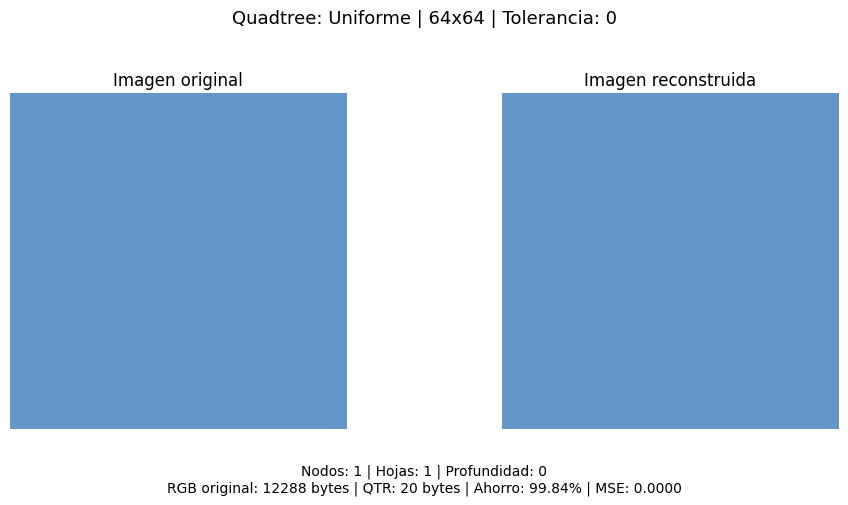

Evidencia guardada: evidencias/evidencia_uniforme_64_tol_0.png
------------------------------------------------------------


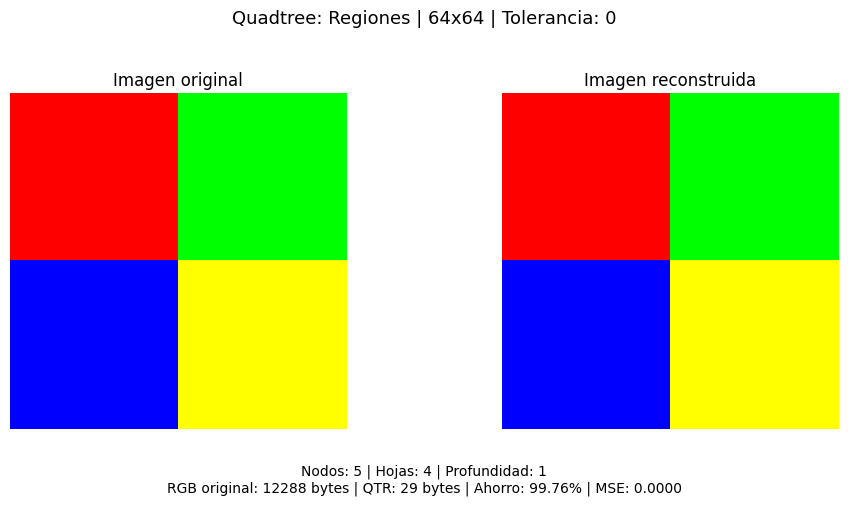

Evidencia guardada: evidencias/evidencia_regiones_64_tol_0.png
------------------------------------------------------------


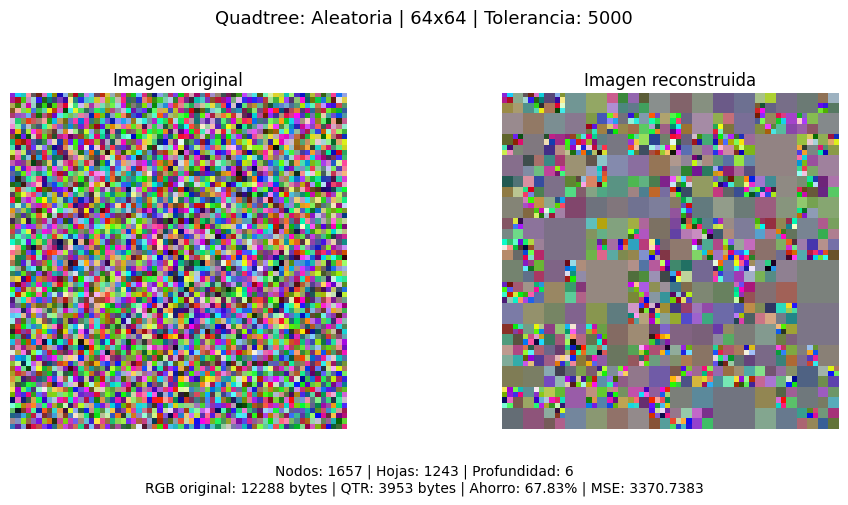

Evidencia guardada: evidencias/evidencia_aleatoria_64_tol_5000.png
------------------------------------------------------------

ARCHIVO ZIP GENERADO: evidencias_quadtree.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
# ENTREGABLE 4: EVIDENCIAS DE FUNCIONAMIENTO

from pathlib import Path
from google.colab import files
import zipfile

carpeta_evidencias = Path("evidencias")
carpeta_evidencias.mkdir(exist_ok=True)

casos_evidencia = [
    ("uniforme", 64, 0),
    ("regiones", 64, 0),
    ("aleatoria", 64, 5000)
]

for tipo, tamaño, tolerancia in casos_evidencia:

    imagen = generar_imagen_prueba(
        tipo, tamaño, semilla=42
    )

    arbol = construir_quadtree(
        imagen, 0, 0, tamaño, tamaño, tolerancia
    )

    nombre_qtr = carpeta_evidencias / (
        f"{tipo}_{tamaño}_tol_{tolerancia}.qtr"
    )

    guardar_quadtree(arbol, nombre_qtr)

    arbol_recuperado = cargar_quadtree(nombre_qtr)
    reconstruida = reconstruir_quadtree(arbol_recuperado)
    metricas = obtener_metricas_arbol(arbol_recuperado)

    mse = np.mean(
        (
            imagen.astype(np.float64)
            - reconstruida.astype(np.float64)
        ) ** 2
    )

    bytes_originales = imagen.nbytes
    bytes_qtr = nombre_qtr.stat().st_size
    ahorro = (1 - bytes_qtr / bytes_originales) * 100

    fig, ejes = plt.subplots(1, 2, figsize=(10, 5))

    ejes[0].imshow(imagen)
    ejes[0].set_title("Imagen original")
    ejes[0].axis("off")

    ejes[1].imshow(reconstruida)
    ejes[1].set_title("Imagen reconstruida")
    ejes[1].axis("off")

    fig.suptitle(
        f"Quadtree: {tipo.capitalize()} | "
        f"{tamaño}x{tamaño} | Tolerancia: {tolerancia}",
        fontsize=13
    )

    informacion = (
        f"Nodos: {metricas['nodos_totales']} | "
        f"Hojas: {metricas['hojas']} | "
        f"Profundidad: {metricas['profundidad_maxima']}\n"
        f"RGB original: {bytes_originales} bytes | "
        f"QTR: {bytes_qtr} bytes | "
        f"Ahorro: {ahorro:.2f}% | MSE: {mse:.4f}"
    )

    fig.text(
        0.5, 0.04, informacion,
        ha="center", va="center", fontsize=10
    )

    fig.tight_layout(rect=[0, 0.11, 1, 0.92])

    ruta_png = carpeta_evidencias / (
        f"evidencia_{tipo}_{tamaño}_tol_{tolerancia}.png"
    )

    fig.savefig(ruta_png, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Evidencia guardada: {ruta_png}")
    print("-" * 60)

# Empaquetar todas las evidencias
nombre_zip = "evidencias_quadtree.zip"

with zipfile.ZipFile(nombre_zip, "w", zipfile.ZIP_DEFLATED) as zipf:
    for archivo in carpeta_evidencias.iterdir():
        if archivo.is_file():
            zipf.write(archivo, arcname=archivo.name)

print("\nARCHIVO ZIP GENERADO:", nombre_zip)

files.download(nombre_zip)

## 10. Uso de Inteligencia Artificial como herramienta de apoyo

### 10.1 Propósito del uso de IA

Durante el desarrollo del proyecto se utilizó inteligencia artificial generativa como herramienta de asistencia técnica y académica, con el propósito de facilitar la comprensión de conceptos, mejorar la organización del código y apoyar la identificación y corrección de errores.

Su utilización se orientó a complementar el proceso de desarrollo, proporcionando explicaciones, propuestas de solución y recomendaciones para mejorar la estructura y presentación del proyecto.

### 10.2 Aplicaciones durante el desarrollo

La inteligencia artificial se empleó principalmente en las siguientes actividades:

- **Organización del proyecto:** apoyo para estructurar el notebook de Google Colab, ordenar las funciones y presentar de manera clara las diferentes etapas del algoritmo.
- **Comprensión del algoritmo:** explicación de la estrategia de Divide y Vencerás, la estructura Quadtree, las condiciones de terminación y el análisis de complejidad mediante el Teorema Maestro.
- **Revisión y depuración:** identificación de posibles errores de programación y propuesta de correcciones, especialmente en el manejo de regiones, la serialización de datos y la recuperación de archivos binarios.
- **Asistencia en la implementación:** generación y revisión de fragmentos de código utilizados como base para determinadas funciones, pruebas y visualizaciones.
- **Validación experimental:** apoyo para diseñar casos de prueba, interpretar los resultados obtenidos y contrastar el comportamiento experimental con el análisis teórico.
- **Documentación:** recomendaciones para mejorar la claridad de las explicaciones, la presentación de tablas, gráficas y conclusiones.

### 10.3 Verificación de los resultados

Las propuestas y correcciones se incorporaron al entorno de desarrollo y se sometieron a pruebas de funcionamiento.

Se realizaron verificaciones con imágenes uniformes, imágenes por regiones, datos aleatorios y dimensiones impares. También se evaluaron diferentes tolerancias, tiempos de ejecución, tamaños de archivo y errores de reconstrucción.

Los resultados fueron obtenidos mediante la ejecución del código en Google Colab y se utilizaron para comprobar el funcionamiento de la implementación.

De esta manera, las respuestas proporcionadas por la herramienta de inteligencia artificial se trataron como propuestas técnicas sujetas a revisión y comprobación, no como resultados experimentales verificados por sí mismos.

### 10.4 Consideraciones sobre el uso responsable

La utilización de inteligencia artificial permitió contar con un recurso adicional para consultar conceptos, explorar alternativas de implementación y resolver dificultades durante el desarrollo.

Sin embargo, se reconoce la importancia de comprender el funcionamiento de las soluciones propuestas, verificar sus resultados y mantener una interpretación crítica de la información generada.

La inteligencia artificial se utilizó como herramienta de apoyo al proceso de aprendizaje y desarrollo, mientras que la evaluación del funcionamiento se fundamentó en pruebas ejecutadas y resultados observables.

### 10.5 Herramienta utilizada

**Herramienta:** ChatGPT, desarrollado por OpenAI.

**Finalidad:** asistencia en programación, depuración, organización del proyecto, explicación de conceptos, interpretación de resultados y documentación técnica.

**Entorno de desarrollo y ejecución:** Python en Google Colab.